In [1]:
# 타이타닉 호 승객 생존 예측 미니 프로젝트 : 1. EDA(분석, 시각화) -> 2. 전처리 -> [3. ML]

In [2]:
%matplotlib inline

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib

In [5]:
# 머신러닝 코딩 5단계
# 1. 훈련 데이터와 테스트 데이터로 나눈다. train_test_split
# 2. 머신러닝 알고리즘을 선택한다. model = DecisionTreeClassifier(), 붕어빵 = 틀(..)
# 3. 훈련, model.fit(...)
# 4. 평가, model.score(...)
# 5. 새로운 데이터로 예측한다. model.predict(...)

In [6]:
df = pd.read_csv('titanic_ok.csv')
df

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,sex2,title
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO",1,Miss
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON",0,Master
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",1,Miss
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON",0,Mr
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",1,Mrs
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1303,3,0,"Zabour, Miss. Hileni",female,14.5000,1,0,2665,14.4542,NaN,C,NaN,328.0,NaN,1,Miss
1304,3,0,"Zabour, Miss. Thamine",female,22.0000,1,0,2665,14.4542,NaN,C,NaN,NaN,NaN,1,Miss
1305,3,0,"Zakarian, Mr. Mapriededer",male,26.5000,0,0,2656,7.2250,NaN,C,NaN,304.0,NaN,0,Mr
1306,3,0,"Zakarian, Mr. Ortin",male,27.0000,0,0,2670,7.2250,NaN,C,NaN,NaN,NaN,0,Mr


In [7]:
# 데이터(X)와 정답(y)를 준비한다.

In [8]:
# X를 얻는다
# [ 선실등급, 성별, 나이, 형제_수, 부모_수, 운임 ]
x_cols = [ 'pclass', 'sex2', 'age', 'sibsp', 'parch', 'fare' ]
X = df[ x_cols ].values # numpy 배열로 리턴
print( X.shape )
X

(1308, 6)


array([[  1.    ,   1.    ,  29.    ,   0.    ,   0.    , 211.3375],
       [  1.    ,   0.    ,   0.9167,   1.    ,   2.    , 151.55  ],
       [  1.    ,   1.    ,   2.    ,   1.    ,   2.    , 151.55  ],
       ...,
       [  3.    ,   0.    ,  26.5   ,   0.    ,   0.    ,   7.225 ],
       [  3.    ,   0.    ,  27.    ,   0.    ,   0.    ,   7.225 ],
       [  3.    ,   0.    ,  29.    ,   0.    ,   0.    ,   7.875 ]])

In [9]:
# y를 얻는다
y = df['survived'].values
y

array([1, 1, 0, ..., 0, 0, 0], dtype=int64)

In [10]:
# 1. 훈련 데이터와 테스트 데이터로 나눈다. train_test_split

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
# 훈련_데이터, 테스트_데이터, 훈련_정답, 테스트_정답 = train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=7)

In [13]:
# 2. 머신러닝 알고리즘을 선택한다. model = DecisionTreeClassifier(), 붕어빵 = 틀(..)

In [14]:
from sklearn.tree import DecisionTreeClassifier

In [15]:
model = DecisionTreeClassifier()

In [16]:
# 3. 훈련, model.fit(...)

In [17]:
model.fit(X_train, y_train) # 홍길동.공부해(문제지, 답안지)

DecisionTreeClassifier()

In [18]:
# 4. 평가, model.score(...)

In [19]:
print("훈련 점수:", model.score(X_train, y_train))
print("테스트 점수:", model.score(X_test, y_test))
# 훈련 점수: 0.9702633814783348
# 테스트 점수: 0.7709923664122137
# 97 - 77 ==> 20 : overfitting

훈련 점수: 0.9702633814783348
테스트 점수: 0.7480916030534351


In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=7)
model = DecisionTreeClassifier(max_depth=6)
model.fit(X_train, y_train)
print(f"훈련 점수: {model.score(X_train, y_train)*100:.1f}점")
print(f"테스트 점수: {model.score(X_test, y_test)*100:.1f}점")
# 83.9 - 84.0 --> -0.1 <== 튜닝 성공!

훈련 점수: 83.9점
테스트 점수: 84.0점


In [21]:
# 5. 새로운 데이터로 예측한다. model.predict(...)

In [22]:
# 디카프리오는 살 수 있었나?
# [[ 3등실, 남:0, 나이:19살, 형제:0, 부모:0, 운임:10파운드 ]]
dicaprio = [[ 3, 0, 19, 0, 0, 10 ]]
result = model.predict_proba(dicaprio)
print(result) # [[0.88970588 0.11029412]] ==> [[ 사망확률 생존확률 ]]
print(f"생존확률: {result[0][1]*100:.1f}%")

[[0.88970588 0.11029412]]
생존확률: 11.0%


In [23]:
# 여주인공 윈슬릿은?
# [[ 1등실, 여:1, 나이:17살, 형제:1, 부모:2, 운임:400파운드 ]]
winslet = [[ 1, 1, 17, 1, 2, 400 ]]
result = model.predict_proba(winslet)
print(result) # [[0.00787402 0.99212598]] ==> [[ 사망확률 생존확률 ]]
print(f"생존확률: {result[0][1]*100:.1f}%")

[[0.00787402 0.99212598]]
생존확률: 99.2%


In [24]:
# 설명가능한 인공지능

In [25]:
from sklearn.tree import plot_tree

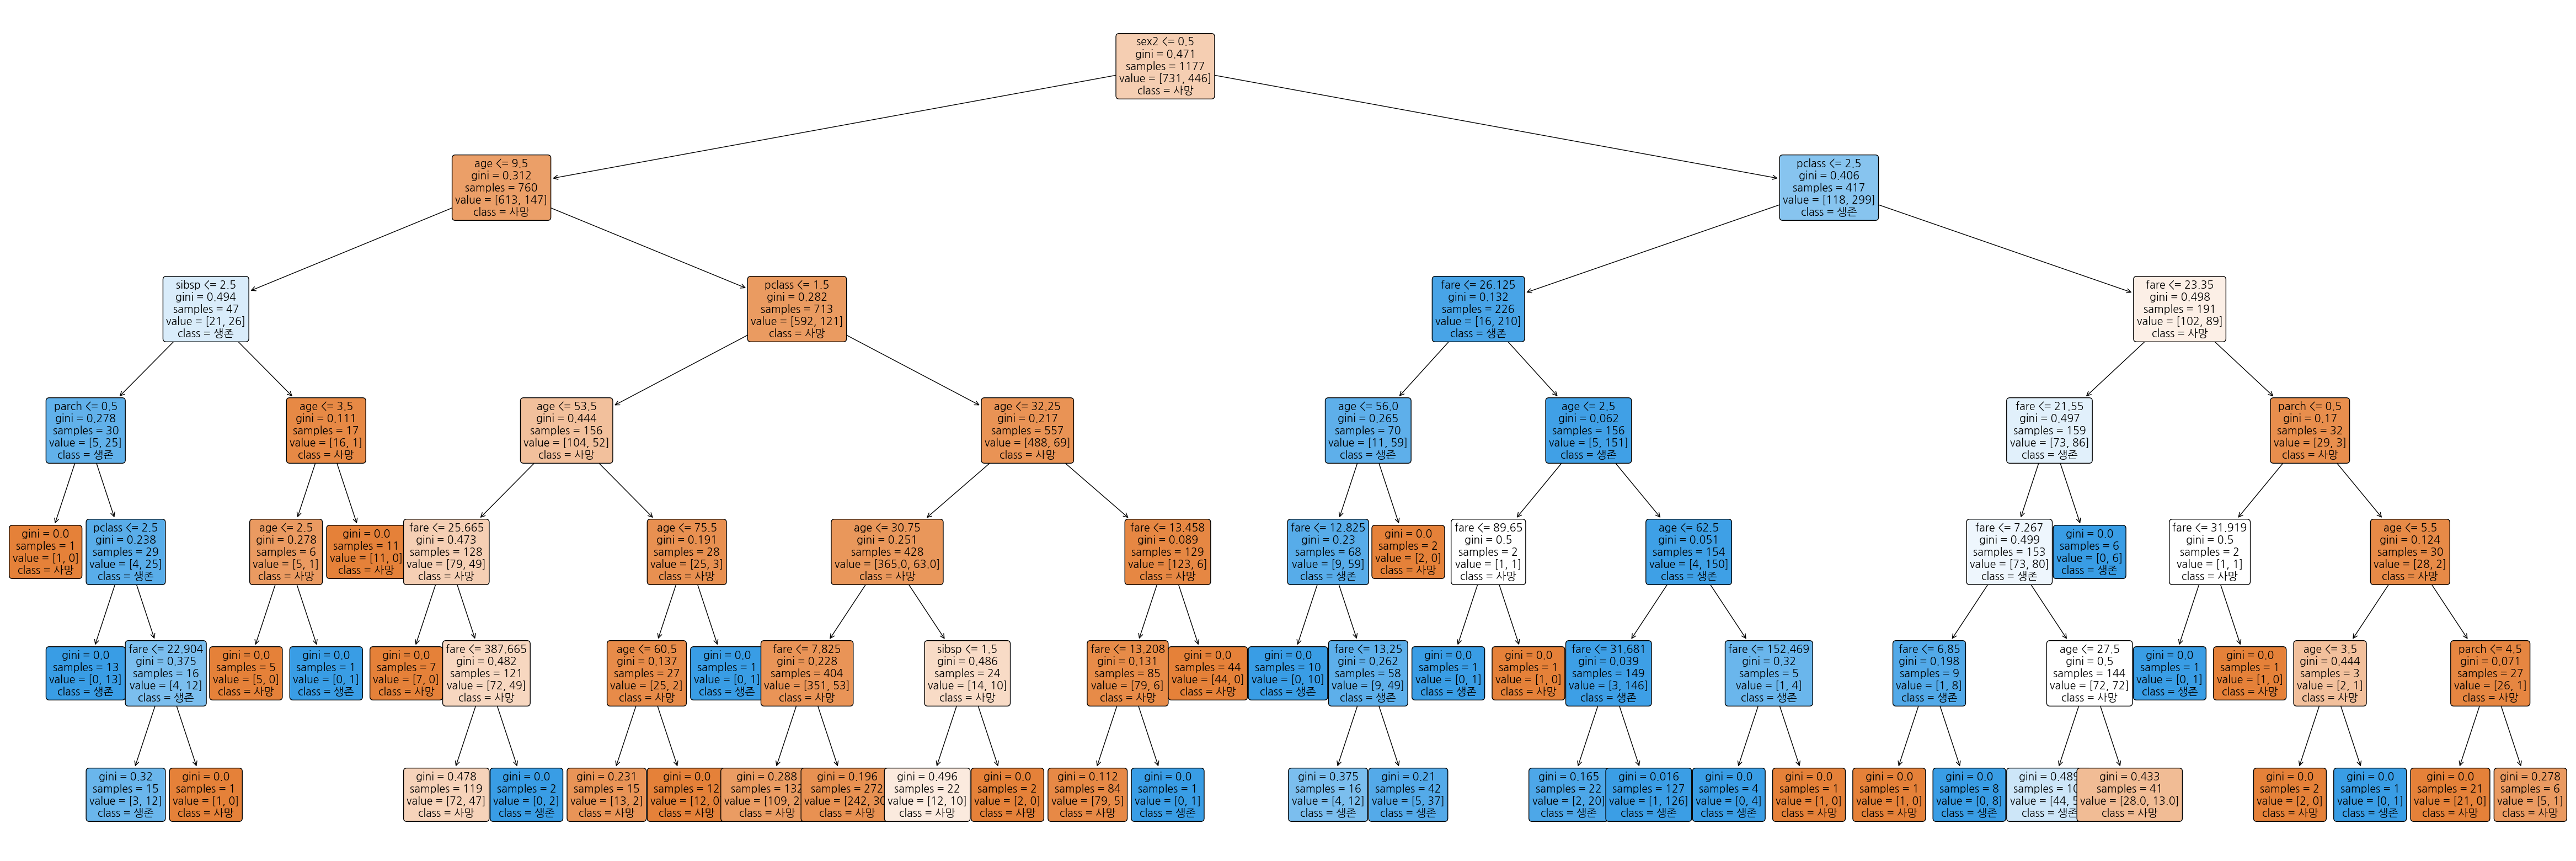

In [26]:
plt.figure(figsize=(60, 20))
plot_tree(model, feature_names=x_cols, class_names=['사망','생존'], filled=True, rounded=True, fontsize=14)
plt.savefig('tree1.png')
plt.show()

In [27]:
# 중요도 확인
print(x_cols)
print(model.feature_importances_)

['pclass', 'sex2', 'age', 'sibsp', 'parch', 'fare']
[0.19523637 0.51459046 0.12444503 0.04801439 0.00836564 0.1093481 ]


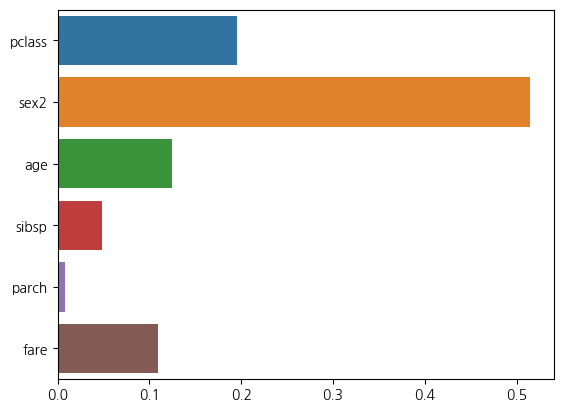

In [28]:
sns.barplot(x=model.feature_importances_, y=x_cols, palette='tab10')
plt.show()

In [29]:
imp = pd.Series(model.feature_importances_, index=x_cols) # 값, 인덱스 지정:컬럼
imp

pclass    0.195236
sex2      0.514590
age       0.124445
sibsp     0.048014
parch     0.008366
fare      0.109348
dtype: float64

In [30]:
imp = imp.sort_values(ascending=False) # 오름차순이 아니다 ==> 내림차순
imp

sex2      0.514590
pclass    0.195236
age       0.124445
fare      0.109348
sibsp     0.048014
parch     0.008366
dtype: float64

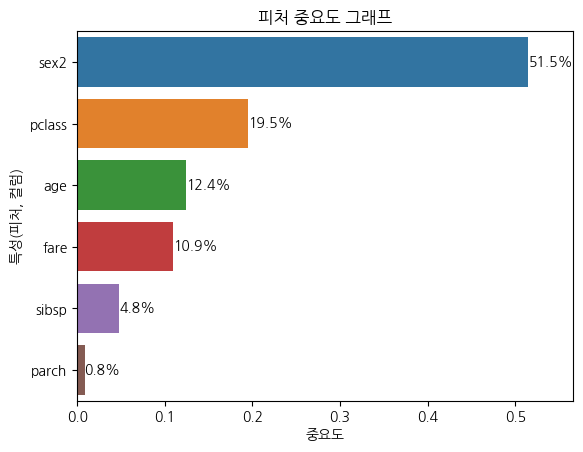

In [31]:
ax = sns.barplot(x=imp, y=imp.index, palette='tab10')
for i in ax.containers:
    ax.bar_label(i, fmt="{:.1%}")
ax.margins(x=0.1) # X축 좌우에 10% 여백 추가
plt.ylabel("특성(피처, 컬럼)")
plt.xlabel("중요도")
plt.title("피처 중요도 그래프")
plt.show() # 4:30~

In [32]:
# end